In [1]:
# เฉลย: ย้ายไปทำงานที่โฟลเดอร์ labs/ (ที่มี data/ และ mlia.py)
import os, sys
if os.path.basename(os.getcwd()) == "solution":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

# Lab 1 · คัดกรองเบาหวานด้วย Logistic Regression (≈ 60 นาที)

**โจทย์:** คลินิกอยากมีเครื่องมือ **คัดกรอง (screening)** ว่าใครควรถูกส่งไปตรวจเบาหวานยืนยัน (เช่น OGTT/HbA1c)
จากค่าที่วัดได้ง่าย ๆ ในการตรวจสุขภาพ — ถ้าเครื่องมือบอกว่า "เสี่ยง" เราจะนัดตรวจละเอียด ถ้าบอกว่า "ไม่เสี่ยง" ก็ไม่ต้องนัด

นี่คือ **binary classification**: ทำนายว่าแต่ละคนอยู่คลาส `1` (เป็นเบาหวาน) หรือ `0` (ไม่เป็น)

| คอลัมน์ | ความหมาย | หน่วย |
|---|---|---|
| `Pregnancies` | จำนวนครั้งที่ตั้งครรภ์ | ครั้ง |
| `Glucose` | ระดับน้ำตาลในเลือด 2 ชม. หลังดื่มน้ำตาล (OGTT) | mg/dL |
| `BloodPressure` | ความดัน diastolic | mmHg |
| `SkinThickness` | ความหนาไขมันใต้ผิวหนังที่ต้นแขน (triceps) | mm |
| `Insulin` | insulin ในเลือด 2 ชม. | µU/mL |
| `BMI` | ดัชนีมวลกาย | kg/m² |
| `DiabetesPedigreeFunction` | คะแนนประวัติเบาหวานในครอบครัว | — |
| `Age` | อายุ | ปี |
| `Outcome` | **target** — 1 = เป็นเบาหวาน (ภายใน 5 ปี), 0 = ไม่เป็น | — |

**วิธีทำ lab:** รันทีละ cell (Shift+Enter) · cell ที่มี `# TODO` ให้เติมโค้ดแทน `___`
· ใต้ TODO มี cell ตรวจคำตอบ ขึ้น ✅ = ไปต่อได้

> ตามไม่ทัน? ทุกหัวข้อมี cell **checkpoint** ให้ uncomment แล้วรัน จะได้ตัวแปรที่ต้องใช้ครบ แล้วทำต่อจากตรงนั้นได้เลย

⚠️ *เพื่อการเรียนรู้เท่านั้น — ไม่ใช่เครื่องมือทางการแพทย์*

*Data: Smith, Everhart, Dickson, Knowler & Johannes (1988). Pima Indians Diabetes Database (originally from NIDDK), via the UCI Machine Learning Repository.*

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlia import load_checkpoint, save_checkpoint, show_check, RANDOM_STATE

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)

## 1.1 โหลดข้อมูล

ข้อมูลอยู่ในไฟล์ `data/diabetes.csv` — 1 แถว = ผู้หญิง 1 คน (อายุ ≥ 21 ปี)

In [3]:
# ✔ TODO 1.1: อ่านไฟล์ data/diabetes.csv ด้วย pd.read_csv แล้วเก็บไว้ในตัวแปร df
df = pd.read_csv("data/diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
show_check("df" in globals() and isinstance(df, pd.DataFrame) and df.shape == (768, 9),
           f"โหลดข้อมูลได้ {len(df):,} แถว × {df.shape[1]} คอลัมน์", "ยังไม่ได้ df ที่ถูกต้อง — ตรวจชื่อไฟล์ (data/diabetes.csv)")

✅ โหลดข้อมูลได้ 768 แถว × 9 คอลัมน์


## 1.2 สำรวจข้อมูล (EDA)

`describe()` สรุปทุกคอลัมน์ในตารางเดียว — **สังเกตค่า `min`** ของ `Glucose`, `BloodPressure`, `BMI` มีใครน้ำตาลในเลือด 0 หรือ BMI 0 ได้จริงไหม?

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845,3.370,0.000,1.000,3.000,6.000,17.00
Glucose,768.0,120.895,31.973,0.000,99.000,117.000,140.250,199.00
BloodPressure,768.0,69.105,19.356,0.000,62.000,72.000,80.000,122.00
SkinThickness,768.0,20.536,15.952,0.000,0.000,23.000,32.000,99.00
Insulin,768.0,79.799,115.244,0.000,0.000,30.500,127.250,846.00
BMI,768.0,31.993,7.884,0.000,27.300,32.000,36.600,67.10
DiabetesPedigreeFunction,768.0,0.472,0.331,0.078,0.244,0.372,0.626,2.42
Age,768.0,33.241,11.760,21.000,24.000,29.000,41.000,81.00
Outcome,768.0,0.349,0.477,0.000,0.000,0.000,1.000,1.00


สัดส่วนของ target สำคัญมาก: ถ้าคลาสไม่สมดุล **accuracy จะหลอกเรา** (เดี๋ยวเห็นในข้อ 1.5)

In [6]:
counts = df["Outcome"].value_counts().sort_index()
print(counts)
print(f"สัดส่วนผู้เป็นเบาหวาน = {df['Outcome'].mean():.1%}")

Outcome
0    500
1    268
Name: count, dtype: int64
สัดส่วนผู้เป็นเบาหวาน = 34.9%


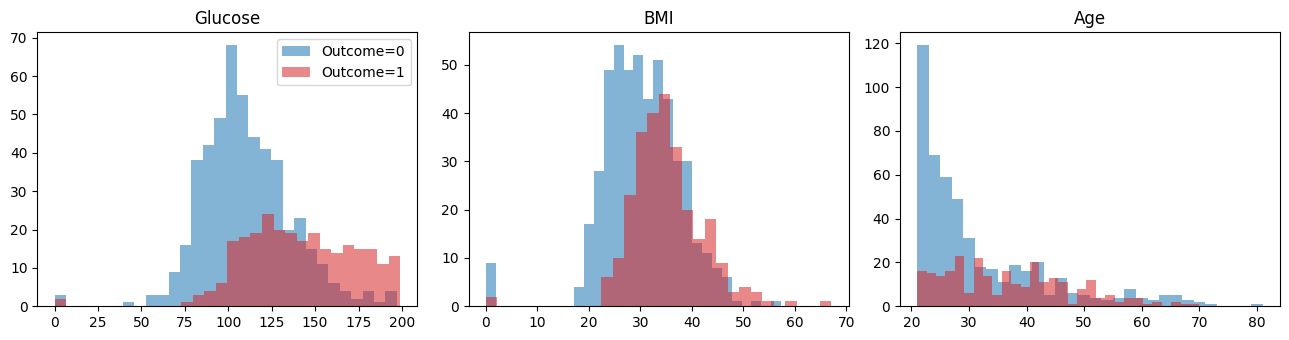

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["Glucose", "BMI", "Age"]):
    for y, color in [(0, "tab:blue"), (1, "tab:red")]:
        ax.hist(df.loc[df["Outcome"] == y, col], bins=30, alpha=0.55, color=color, label=f"Outcome={y}")
    ax.set(title=col)
axes[0].legend()
plt.tight_layout(); plt.show()

**สังเกต:** คนที่เป็นเบาหวาน (สีแดง) มี `Glucose` สูงกว่าอย่างชัดเจน — feature นี้น่าจะสำคัญที่สุด
และมีแท่งที่ `0` ใน `Glucose` กับ `BMI` ซึ่งเป็นไปไม่ได้ทางสรีรวิทยา

## 1.3 ทำความสะอาด: 0 ที่จริง ๆ คือ "ไม่ได้วัด"

ในชุดข้อมูลนี้ ค่า `0` ของ 5 คอลัมน์ข้างล่างหมายถึง **missing value** (ไม่ได้บันทึก) ไม่ใช่ค่าศูนย์จริง
ถ้าปล่อยไว้ model จะเรียนว่า "BMI = 0" เป็นเรื่องปกติ — เราจะแปลงเป็น `NaN` แล้วให้ pipeline เติมค่าให้ทีหลัง

(`Pregnancies = 0` เป็นค่าจริง ไม่ต้องแปลง)

In [8]:
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# ✔ TODO 1.3: แทนค่า 0 ในคอลัมน์ ZERO_AS_MISSING ด้วย np.nan (ใช้ .replace(0, np.nan))
df[ZERO_AS_MISSING] = df[ZERO_AS_MISSING].replace(0, np.nan)
df.isna().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [9]:
show_check(df["Insulin"].isna().sum() == 374 and df["Glucose"].isna().sum() == 5,
           "แปลง 0 → NaN แล้ว (Insulin หายไป 374 แถว!)", "ยังไม่ได้แปลง — ตรวจว่าใช้ df[ZERO_AS_MISSING].replace(0, np.nan)")

✅ แปลง 0 → NaN แล้ว (Insulin หายไป 374 แถว!)


`Insulin` หายเกือบครึ่ง และ `SkinThickness` หายเกือบ 30% — เราจะ **ไม่ลบแถวทิ้ง** (ข้อมูลน้อยอยู่แล้ว)
แต่ใช้ `SimpleImputer` เติมค่า median ของ **ชุด train** ใน pipeline

ตอนนี้แยก feature (`X`) กับ target (`y`)

In [10]:
FEATURES = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI",
            "DiabetesPedigreeFunction", "Age"]
X = df[FEATURES]
y = df["Outcome"]
save_checkpoint("lab1-4", df=df, X=X, y=y)

## 1.4 แบ่ง train / test

- **train set** (80%) ใช้สอน model และเลือกค่าต่าง ๆ
- **test set** (20%) เก็บไว้ **ใช้ครั้งเดียวตอนท้าย** เหมือนข้อสอบจริงที่ห้ามดูก่อน
- `stratify=y` ทำให้สัดส่วนผู้เป็นเบาหวานใน train และ test เท่ากัน (~35%)
- `random_state=RANDOM_STATE` (= 42) ทำให้ผลเหมือนกันทุกเครื่อง

In [11]:
# ตามไม่ทัน? uncomment บรรทัดล่างแล้วรัน
# df, X, y = load_checkpoint("lab1-4")

from sklearn.model_selection import train_test_split

# ✔ TODO 1.4: ใช้ train_test_split แบ่ง X, y ด้วย test_size=0.2, stratify=y, random_state=RANDOM_STATE
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
print(f"train: {y_train.mean():.1%} เป็นเบาหวาน · test: {y_test.mean():.1%}")

(614, 8) (154, 8)
train: 34.9% เป็นเบาหวาน · test: 35.1%


In [12]:
show_check(len(X_test) == 154 and abs(y_train.mean() - y_test.mean()) < 0.01,
           "แบ่งได้ train 614 / test 154 และสัดส่วนเท่ากัน", "ตรวจ test_size=0.2 และ stratify=y")
save_checkpoint("lab1-5", X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

✅ แบ่งได้ train 614 / test 154 และสัดส่วนเท่ากัน


## 1.5 Baseline: model ที่ "ไม่ฉลาดเลย"

ก่อนสร้าง model จริง ต้องรู้ก่อนว่า **ทำแบบมักง่ายที่สุดได้ผลเท่าไร** — `DummyClassifier` ตอบคลาสที่พบบ่อยที่สุด (`0`) ให้ทุกคน

In [13]:
# ตามไม่ทัน? uncomment บรรทัดล่างแล้วรัน
# X_train, X_test, y_train, y_test = load_checkpoint("lab1-5")

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred = dummy.predict(X_test)
print(f"accuracy = {accuracy_score(y_test, pred):.1%}")
print(f"recall   = {recall_score(y_test, pred):.1%}   ← หาผู้ป่วยเจอกี่ % ของผู้ป่วยทั้งหมด")

accuracy = 64.9%
recall   = 0.0%   ← หาผู้ป่วยเจอกี่ % ของผู้ป่วยทั้งหมด


**accuracy 65%** ฟังดูพอใช้ แต่ model นี้ **ไม่เจอผู้ป่วยเลยสักคน** (recall = 0%)
งานคัดกรองต้องการ **recall สูง** — พลาดผู้ป่วย (false negative) แพงกว่านัดคนปกติมาตรวจเพิ่ม (false positive)

## 1.6 Logistic regression ใน Pipeline

**Logistic regression** รวม feature เป็นคะแนนเชิงเส้น $z = b_0 + b_1x_1 + \dots + b_8x_8$
แล้วบีบด้วย **sigmoid** $p = 1/(1+e^{-z})$ ให้เป็นความน่าจะเป็น 0–1

เราจะต่อ 3 ขั้นเป็น **Pipeline** เดียว เพื่อให้ทุกขั้น `fit` จาก train เท่านั้น (กัน data leakage) และนำไป deploy ได้ทั้งก้อน:

1. `SimpleImputer(strategy="median")` เติม NaN ด้วย median
2. `StandardScaler()` ปรับทุก feature ให้ mean = 0, SD = 1 (logistic regression ที่มี regularization ต้องการ)
3. `LogisticRegression(max_iter=1000)`

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ✔ TODO 1.6: สร้าง pipeline ด้วย make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)) แล้ว fit กับ X_train, y_train
logreg = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)
logreg

,steps,"[('simpleimputer', ...), ('standardscaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [15]:
show_check(hasattr(logreg, "classes_") and len(logreg.steps) == 3, "fit pipeline 3 ขั้นแล้ว", "ยังไม่ได้ fit pipeline 3 ขั้น")

✅ fit pipeline 3 ขั้นแล้ว


`predict_proba` คืนความน่าจะเป็นของทั้งสองคลาส — คอลัมน์ `[:, 1]` คือความน่าจะเป็นที่ **เป็นเบาหวาน**
ส่วน `predict` ตัดสินด้วย threshold 0.5 ให้อัตโนมัติ

In [16]:
proba_test = logreg.predict_proba(X_test)[:, 1]
pd.DataFrame({"p(diabetes)": proba_test[:6], "predict (≥0.5)": logreg.predict(X_test)[:6], "จริง": y_test.values[:6]})

,p(diabetes),predict (≥0.5),จริง
0,0.610,1,0
1,0.118,0,0
2,0.293,0,0
3,0.251,0,1
4,0.034,0,0
5,0.168,0,0


In [17]:
save_checkpoint("lab1-7", X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test, logreg=logreg)

## 1.7 วัดผล: confusion matrix, precision, recall, ROC-AUC

| | ทำนาย 0 | ทำนาย 1 |
|---|---|---|
| **จริง 0** | TN | FP (นัดคนปกติมาตรวจ) |
| **จริง 1** | FN (พลาดผู้ป่วย!) | TP |

- **recall (sensitivity)** = TP / (TP + FN) — ผู้ป่วยทั้งหมด เราเจอกี่ %
- **precision (PPV)** = TP / (TP + FP) — คนที่เราบอกว่าเสี่ยง เป็นจริงกี่ %
- **ROC-AUC** — ความสามารถจัดอันดับ "คนป่วยได้คะแนนสูงกว่าคนปกติ" ไม่ขึ้นกับ threshold (0.5 = เดาสุ่ม, 1 = สมบูรณ์)

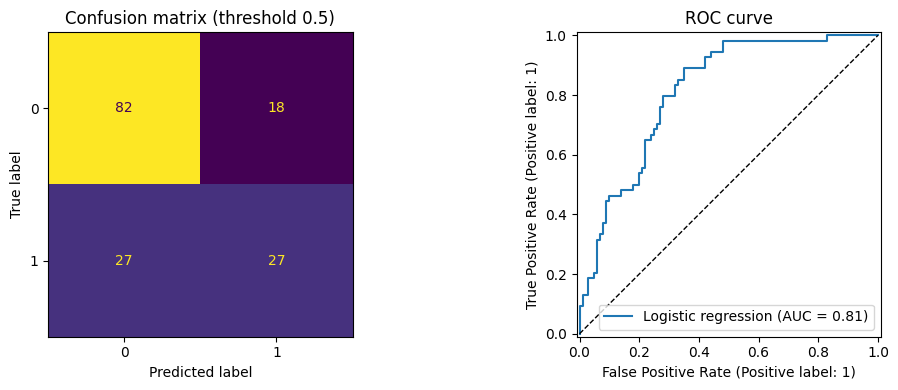

              precision    recall  f1-score   support

           0      0.752     0.820     0.785       100
           1      0.600     0.500     0.545        54

    accuracy                          0.708       154
   macro avg      0.676     0.660     0.665       154
weighted avg      0.699     0.708     0.701       154



In [18]:
# ตามไม่ทัน? uncomment บรรทัดล่างแล้วรัน
# X_train, X_test, y_train, y_test, logreg = load_checkpoint("lab1-7")

from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_auc_score, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_estimator(logreg, X_test, y_test, ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (threshold 0.5)")
RocCurveDisplay.from_estimator(logreg, X_test, y_test, ax=axes[1], name="Logistic regression")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC curve")
plt.tight_layout(); plt.show()

print(classification_report(y_test, logreg.predict(X_test), digits=3))

In [19]:
# ✔ TODO 1.7: คำนวณ ROC-AUC บน test ด้วย roc_auc_score(y_test, proba_test) เก็บไว้ใน auc_lr
auc_lr = roc_auc_score(y_test, proba_test)
print(f"ROC-AUC = {auc_lr:.3f}")

ROC-AUC = 0.813


In [20]:
show_check(0.8 < auc_lr < 0.9, f"ROC-AUC = {auc_lr:.3f}", "ยังคำนวณไม่ถูก — ใช้ความน่าจะเป็น (proba_test) ไม่ใช่ predict")

✅ ROC-AUC = 0.813


**คำถาม:** ที่ threshold 0.5 recall ของคลาส 1 อยู่ราว 0.5 — แปลว่าพลาดผู้ป่วยไป **ครึ่งหนึ่ง** รับได้ไหมสำหรับงานคัดกรอง?

## 1.8 เลือก threshold สำหรับงานคัดกรอง

threshold 0.5 ไม่ได้ศักดิ์สิทธิ์ — เราเลือกเองได้ตามต้นทุนของความผิดพลาด
เป้าหมาย: **recall ≥ 0.80** แล้วเลือก threshold ที่ precision สูงสุดภายใต้เงื่อนไขนั้น

⚠️ **ห้ามเลือก threshold จาก test set** (เหมือนแอบดูข้อสอบ) — เราใช้ `cross_val_predict` บน **train** เพื่อได้ความน่าจะเป็นแบบ
"out-of-fold" (แต่ละแถวถูกทำนายโดย model ที่ไม่เคยเห็นแถวนั้น) แล้วค่อยเลือก threshold จากตรงนั้น

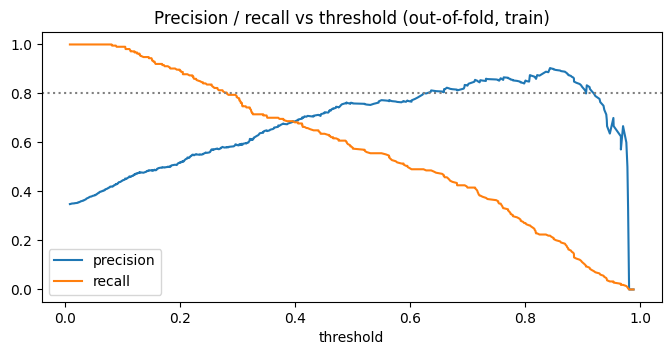

In [21]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof = cross_val_predict(logreg, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(thr, prec[:-1], label="precision")
ax.plot(thr, rec[:-1], label="recall")
ax.axhline(0.8, color="gray", ls=":")
ax.set(xlabel="threshold", title="Precision / recall vs threshold (out-of-fold, train)")
ax.legend(); plt.show()

In [22]:
TARGET_RECALL = 0.80

# ✔ TODO 1.8: หา threshold ที่ใหญ่ที่สุดซึ่งยังให้ recall ≥ TARGET_RECALL  (hint: thr[rec[:-1] >= TARGET_RECALL].max())
threshold = thr[rec[:-1] >= TARGET_RECALL].max()
print(f"threshold ที่เลือก = {threshold:.3f}")

threshold ที่เลือก = 0.281


In [23]:
show_check(0.15 < threshold < 0.45, f"threshold = {threshold:.3f} (ต่ำกว่า 0.5 → เตือนบ่อยขึ้น เจอผู้ป่วยมากขึ้น)",
           "threshold ดูแปลก — ตรวจว่าใช้ rec[:-1] (ยาวเท่ากับ thr)")

✅ threshold = 0.281 (ต่ำกว่า 0.5 → เตือนบ่อยขึ้น เจอผู้ป่วยมากขึ้น)


ตอนนี้ (ครั้งเดียว!) ลองใช้ threshold นี้บน test set เทียบกับ 0.5

In [24]:
from sklearn.metrics import precision_score

rows = []
for name, t in [("default 0.5", 0.5), ("screening", threshold)]:
    pred = (proba_test >= t).astype(int)
    rows.append({"threshold": round(t, 3), "recall": recall_score(y_test, pred),
                 "precision": precision_score(y_test, pred), "accuracy": accuracy_score(y_test, pred),
                 "นัดตรวจ (คน)": pred.sum()})
pd.DataFrame(rows, index=["default 0.5", "screening"])

,threshold,recall,precision,accuracy,นัดตรวจ (คน)
default 0.5,0.500,0.500,0.600,0.708,45
screening,0.281,0.833,0.577,0.727,78


**trade-off:** threshold ต่ำลง → เจอผู้ป่วยมากขึ้น (recall ↑) แต่นัดคนปกติมาตรวจมากขึ้น (precision ↓)
การเลือกจุดนี้คือ **การตัดสินใจทางคลินิก/ธุรกิจ** ไม่ใช่แค่ตัวเลข

## 1.9 อ่าน model: coefficient และ odds ratio

เพราะเรา scale ทุก feature แล้ว coefficient แต่ละตัวคือผลของการเพิ่ม feature นั้น **1 SD** ต่อ log-odds
`exp(coef)` = **odds ratio** เช่น 3.0 แปลว่า odds ของการเป็นเบาหวานเพิ่มเป็น 3 เท่าเมื่อ feature เพิ่ม 1 SD (ตัวอื่นคงที่)

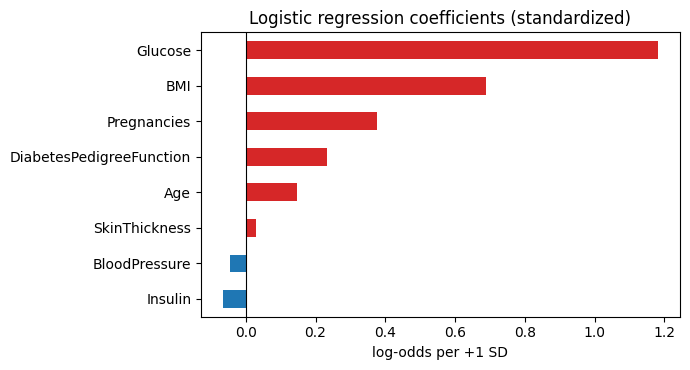

,odds ratio per +1 SD
Glucose,3.263
BMI,1.991
Pregnancies,1.459
DiabetesPedigreeFunction,1.263
Age,1.159
SkinThickness,1.029
BloodPressure,0.957
Insulin,0.936


In [25]:
coef = pd.Series(logreg[-1].coef_[0], index=FEATURES).sort_values()
odds = np.exp(coef).rename("odds ratio per +1 SD")

fig, ax = plt.subplots(figsize=(7, 3.8))
coef.plot.barh(ax=ax, color=["tab:blue" if c < 0 else "tab:red" for c in coef])
ax.axvline(0, color="k", lw=0.8)
ax.set(title="Logistic regression coefficients (standardized)", xlabel="log-odds per +1 SD")
plt.tight_layout(); plt.show()
odds.sort_values(ascending=False).to_frame()

**สรุป Lab 1**

- ข้อมูลจริงมี "0 ที่แปลว่า missing" — ต้องรู้ความหมายของข้อมูลก่อนสร้าง model
- accuracy หลอกได้เมื่อคลาสไม่สมดุล → ดู recall / precision / ROC-AUC
- Pipeline = imputer → scaler → model ทำให้ไม่ leak และพร้อม deploy
- threshold เลือกตามต้นทุนของความผิดพลาด และเลือกจาก **train (CV)** ไม่ใช่ test

**คำถามชวนคิด:** coefficient ของ `Insulin` ติดลบเล็กน้อย — แปลว่า insulin สูงช่วยป้องกันเบาหวานไหม? (hint: missing 49% + correlation กับ Glucose)

ต่อไป Lab 2: model ที่ไม่ใช่เส้นตรง — **Random Forest**

In [26]:
save_checkpoint("lab1-end", X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test, logreg=logreg, threshold=threshold)